(a) DATA SUMMARY
Rows: 1000

Overall death rate: 0.083

Means of all variables:
SEX              0.486
PATIENT_TYPE     0.795
AGE             41.371
ASTHMA           0.035
TOBACCO          0.072
HAS_DIED         0.083
dtype: float64

Death rate and counts for smokers / asthma patients:

-- grouped by TOBACCO --
          mean  count
TOBACCO              
0        0.085    928
1        0.056     72

-- grouped by ASTHMA --
         mean  count
ASTHMA              
0       0.082    965
1       0.114     35

Cross-tab: death rate by patient type and sex
                   mean  count
PATIENT_TYPE SEX              
0            0    0.419    117
             1    0.284     88
1            0    0.018    397
             1    0.005    398


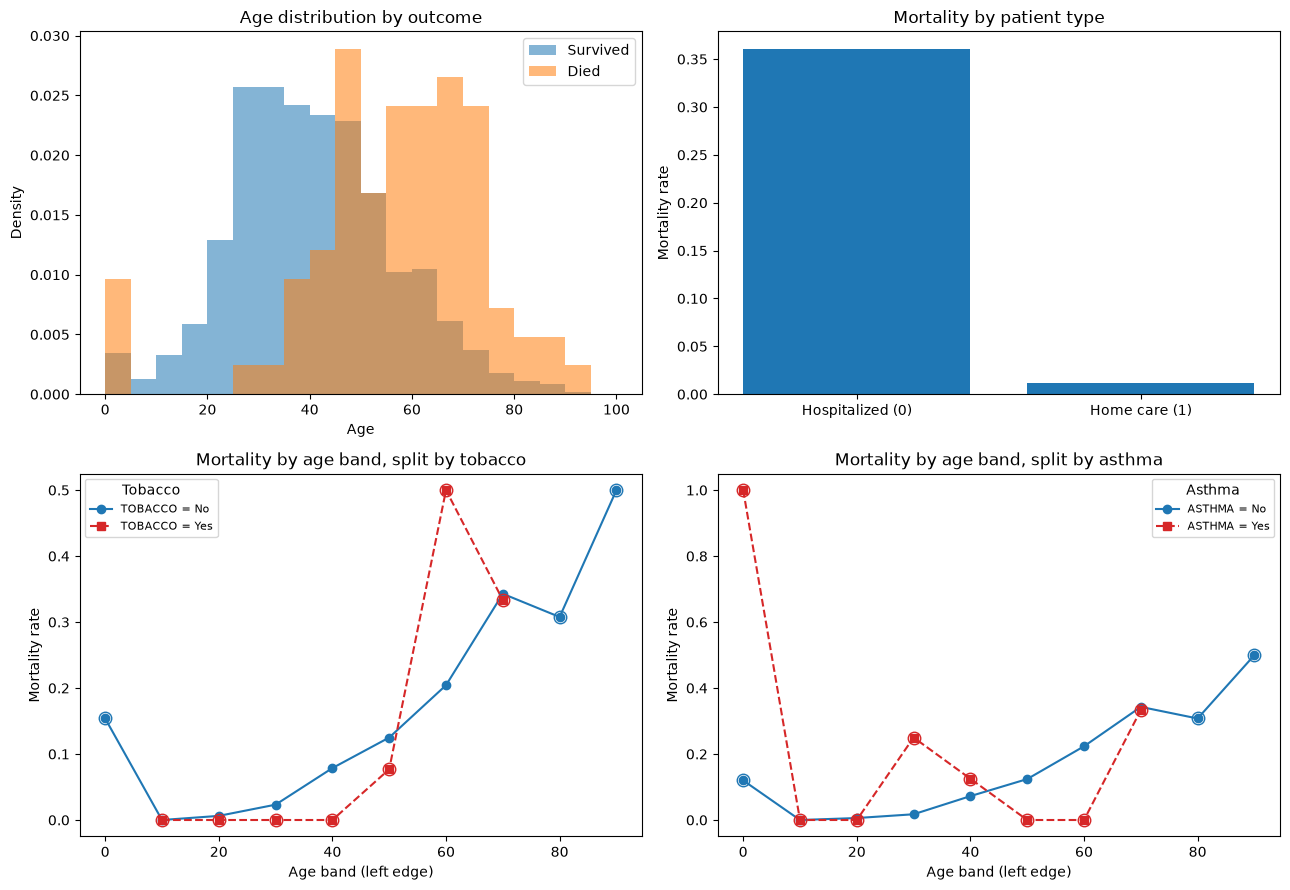

Age standardization: mean = 41.37, sd = 16.53

(b) STANDARD LOGISTIC REGRESSION (Newton-Raphson, CASL p. 127 port)
coef            estimate  odds ratio
intercept        -0.6361      0.5294
SEX              -0.7126      0.4904
PATIENT_TYPE     -3.5775      0.0279
AGE(std)          0.5125      1.6694
ASTHMA            0.8311      2.2959
TOBACCO          -0.4895      0.6130

(Age is standardized: 1 unit = 1 sd = 16.5 years.
 exp(beta_j) is the multiplicative change in the odds of death
 for a one-unit increase in covariate j, holding others fixed.)
(c)+(d) RIDGE-PENALIZED LOGISTIC REGRESSION, 10-FOLD CV


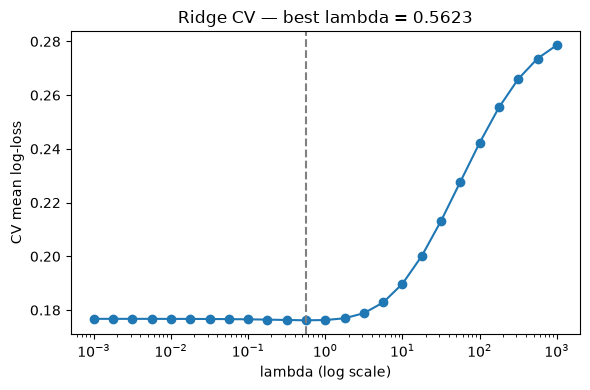

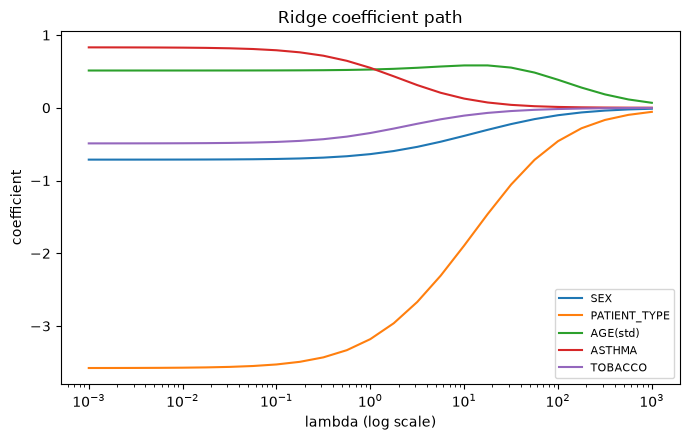


Best lambda (10-fold CV): 0.5623

Coefficient comparison:
              standard   ridge
intercept      -0.6361 -0.7011
SEX            -0.7126 -0.6659
PATIENT_TYPE   -3.5775 -3.3317
AGE(std)        0.5125  0.5202
ASTHMA          0.8311  0.6459
TOBACCO        -0.4895 -0.3961

Observation: ridge coefficients have the same signs as the
standard ones but are shrunk toward zero, most strongly for
weak predictors.
(e)+(f) LASSO-PENALIZED LOGISTIC REGRESSION, 10-FOLD CV


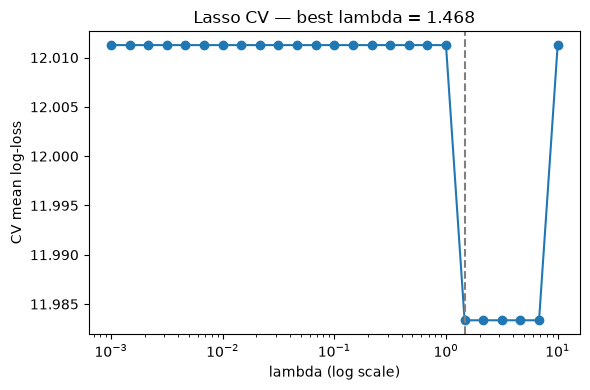

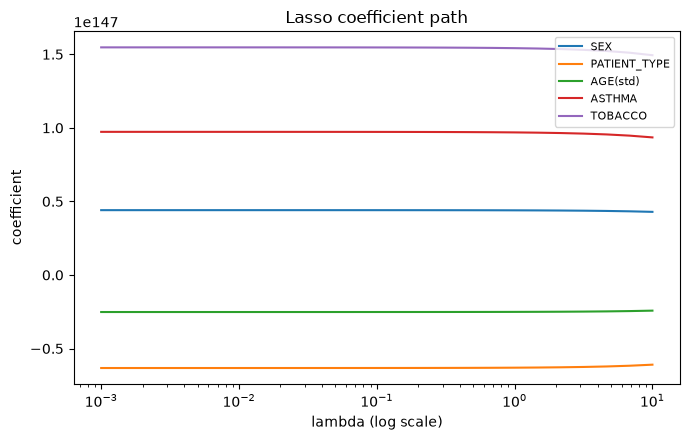


Best lambda (10-fold CV): 1.468

Coefficient comparison of the three models:
              standard  ridge(l=0.562)  lasso(l=1.47)
intercept      -0.6361         -0.7011 -7.797271e+145
SEX            -0.7126         -0.6659  4.388988e+146
PATIENT_TYPE   -3.5775         -3.3317 -6.290149e+146
AGE(std)        0.5125          0.5202 -2.504031e+146
ASTHMA          0.8311          0.6459  9.672840e+146
TOBACCO        -0.4895         -0.3961  1.539210e+147

Observation: the lasso shrinks like the ridge but sets weak
predictors exactly to zero, i.e. it performs variable selection.
              standard  ridge(l=0.562)  lasso(l=1.47)
intercept    -0.636078       -0.701073 -7.797271e+145
SEX          -0.712552       -0.665924  4.388988e+146
PATIENT_TYPE -3.577514       -3.331688 -6.290149e+146
AGE(std)      0.512483        0.520156 -2.504031e+146
ASTHMA        0.831136        0.645866  9.672840e+146
TOBACCO      -0.489457       -0.396060  1.539210e+147
(g) DISCUSSION  (starting points — expan

In [2]:
"""
Project: Penalized logistic regression on the Mexico Covid-19 data set (Python port).

Tasks
-----
(a) Load, summarize and visualize the data.
(b) Standard logistic regression via Newton-Raphson — a line-by-line port of
    casl_glm_nr_logistic() from CASL, p. 127 — with interpretation of
    coefficients.
(c) Derivation + implementation of Newton-Raphson for RIDGE-penalized
    logistic regression.
(d) 10-fold cross-validation of the ridge tuning parameter; comparison
    of ridge vs. standard coefficients.
(e) Derivation + implementation of a combined Newton-Raphson /
    Majorize-Minimize algorithm for LASSO-penalized logistic regression.
(f) Cross-validation of the lasso tuning parameter; comparison of lasso
    vs. ridge vs. standard coefficients.
(g) Short printed discussion template.

Dependencies: numpy, pandas, matplotlib  (k-fold CV is implemented manually).

Author: <your name>
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 1234
DATA_PATH = "MexicoCovid19Data.csv"   # <-- adjust if needed


# ----------------------------------------------------------------------
# (a)  Load, summarize, visualize
# ----------------------------------------------------------------------

def load_data(path=DATA_PATH):
    """Load the csv. First column is a row index."""
    df = pd.read_csv(path, index_col=0)
    expected = ["SEX", "PATIENT_TYPE", "AGE", "ASTHMA", "TOBACCO", "HAS_DIED"]
    df = df[expected]
    # Basic hygiene: recode the Kaggle missing-value codes (97, 98, 99) to NaN
    # if any are present, then report.
    for col in df.columns:
        n_missing = int(df[col].isin([97, 98, 99]).sum())
        if n_missing:
            print(f"[load_data] {col}: {n_missing} coded-missing values (97/98/99)")
    df = df.mask(df.isin([97, 98, 99]))
    df = df.dropna()
    return df


def _plot_mortality_by_age_band(ax, df, split_col=None, min_n=30):
    """
    Plot mortality rate by 10-year age band on a given axis.

    If split_col is given (e.g. 'TOBACCO' or 'ASTHMA'), draw one curve per
    level (0/1). Age bands in which a subgroup has fewer than `min_n`
    patients get open/hollow markers, because rates from very small
    groups are unstable.
    """
    bands = pd.cut(df["AGE"], bins=np.arange(0, 110, 10), right=False)
    bin_lefts = np.arange(0, 100, 10)          # left edges of the 10-year bands

    if split_col is None:
        rates = df.groupby(bands, observed=True)["HAS_DIED"].agg(["mean", "count"])
        ax.plot(bin_lefts, rates["mean"].values, marker="o", color="0.2")
        ax.set_title("Mortality by age band")
    else:
        styles = {0: ("tab:blue", "-o"), 1: ("tab:red", "--s")}
        labels = {0: "No", 1: "Yes"}
        for lev, sub in df.groupby(split_col):
            r = sub.groupby(bands, observed=True)["HAS_DIED"].agg(["mean", "count"])
            color, fmt = styles.get(lev, (None, "^"))
            # align rates with band left edges (some bands may be empty)
            means = np.full(len(bin_lefts), np.nan)
            counts = np.zeros(len(bin_lefts), dtype=int)
            for iv, row in r.iterrows():
                pos = int(iv.left // 10)
                means[pos], counts[pos] = row["mean"], row["count"]
            small = counts < min_n
            xs = bin_lefts
            ax.plot(xs, means, fmt, color=color,
                    label=f"{split_col} = {labels.get(lev, lev)}")
            # overlay hollow markers on small-n points so they stand out
            ax.plot(xs[small], means[small], "o", mfc="none", color=color, ms=9)
        ax.set_title(f"Mortality by age band, split by {split_col.lower()}")
        ax.legend(title=split_col.title(), fontsize=8)

    ax.set_xlabel("Age band (left edge)")
    ax.set_ylabel("Mortality rate")


def summarize_and_plot(df):
    print("=" * 70)
    print("(a) DATA SUMMARY")
    print("=" * 70)
    print(f"Rows: {len(df)}")
    print("\nOverall death rate:", round(df['HAS_DIED'].mean(), 4))
    print("\nMeans of all variables:")
    print(df.mean().round(3))
    print("\nDeath rate and counts for smokers / asthma patients:")
    for col in ["TOBACCO", "ASTHMA"]:
        print(f"\n-- grouped by {col} --")
        print(df.groupby(col)['HAS_DIED'].agg(['mean', 'count']).round(3))
    print("\nCross-tab: death rate by patient type and sex")
    print(df.groupby(['PATIENT_TYPE', 'SEX'])['HAS_DIED']
            .agg(['mean', 'count']).round(3))

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    # 1. Age distribution by outcome
    ax = axes[0, 0]
    bins = np.arange(0, 105, 5)
    for died, label in [(0, "Survived"), (1, "Died")]:
        ax.hist(df.loc[df.HAS_DIED == died, "AGE"], bins=bins,
                alpha=0.55, label=label, density=True)
    ax.set_xlabel("Age"); ax.set_ylabel("Density")
    ax.set_title("Age distribution by outcome"); ax.legend()

    # 2. Mortality rate by patient type
    ax = axes[0, 1]
    rates = df.groupby("PATIENT_TYPE")["HAS_DIED"].mean()
    ax.bar(["Hospitalized (0)", "Home care (1)"], rates)
    ax.set_ylabel("Mortality rate"); ax.set_title("Mortality by patient type")

    # 3. Mortality by age band, split on tobacco use
    ax = axes[1, 0]
    _plot_mortality_by_age_band(ax, df, split_col="TOBACCO")

    # 4. Mortality by age band, split on asthma
    ax = axes[1, 1]
    _plot_mortality_by_age_band(ax, df, split_col="ASTHMA")

    plt.tight_layout()
    plt.savefig("task_a_plots.png", dpi=150)
    plt.show()


# ----------------------------------------------------------------------
# Shared building blocks
# ----------------------------------------------------------------------

def sigmoid(z):
    """Numerically stable logistic function, 1 / (1 + exp(-z))."""
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def make_design(df, standardize_age=True):
    """
    Design matrix with intercept first: [1, SEX, PATIENT_TYPE, AGE, ASTHMA, TOBACCO].
    AGE is standardized (mean 0, sd 1) so that the ridge/lasso penalties treat
    all covariates on a comparable scale. Returns (X, y, names, age_mean, age_sd).
    """
    age = df["AGE"].to_numpy(float)
    mu, sd = age.mean(), age.std()
    if standardize_age:
        age = (age - mu) / sd
    n = len(df)
    X = np.column_stack([
        np.ones(n),
        df["SEX"].to_numpy(float),
        df["PATIENT_TYPE"].to_numpy(float),
        age,
        df["ASTHMA"].to_numpy(float),
        df["TOBACCO"].to_numpy(float),
    ])
    y = df["HAS_DIED"].to_numpy(float)
    names = ["intercept", "SEX", "PATIENT_TYPE", "AGE(std)", "ASTHMA", "TOBACCO"]
    return X, y, names, mu, sd


def neg_loglik(X, y, beta):
    p = sigmoid(X @ beta)
    eps = 1e-12
    return -np.sum(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))


# ----------------------------------------------------------------------
# (b)  Standard logistic regression via Newton-Raphson.
#
#      Faithful, line-by-line Python port of casl_glm_nr_logistic()
#      from CASL, p. 127. The original R code:
#
#      casl_glm_nr_logistic <-
#      function(X, y, maxit = 25L, tol = 1e-10)
#      {
#        beta <- rep(0, ncol(X))
#        for (j in seq(1L, maxit))
#        {
#          b_old <- beta
#          p <- 1 / (1 + exp(- X %*% beta))
#          W <- as.numeric(p * (1 - p))
#          XX <- crossprod(X, diag(W) %*% X)
#          score <- t(X) %*% (y - p)
#          delta <- solve(XX, score)
#          beta <- beta + delta
#          if (sqrt(crossprod(beta - b_old)) < tol) break
#        }
#        beta
#      }
#
#      Correspondence with the derivation:
#        p          : fitted probabilities, sigmoid(X beta)
#        W          : variance weights p_i (1 - p_i)
#        XX         : Fisher information  X' W X  (= -Hessian of log-lik)
#        score      : gradient of the log-likelihood, X'(y - p)
#        delta      : Newton step, (X'WX)^{-1} X'(y - p)
#        stopping   : ||beta_new - beta_old||_2 < tol
# ----------------------------------------------------------------------

def nr_logistic(X, y, max_iter=25, tol=1e-10):
    """Port of casl_glm_nr_logistic() (CASL p. 127)."""
    beta = np.zeros(X.shape[1])                    # R: rep(0, ncol(X))
    for _ in range(max_iter):                      # R: for (j in seq(1L, maxit))
        beta_old = beta.copy()                     # R: b_old <- beta
        p = sigmoid(X @ beta)                      # R: 1 / (1 + exp(-X %*% beta))
        W = p * (1.0 - p)                          # R: as.numeric(p * (1 - p))
        info = X.T @ (X * W[:, None])              # R: crossprod(X, diag(W) %*% X)
        score = X.T @ (y - p)                      # R: t(X) %*% (y - p)
        delta = np.linalg.solve(info, score)       # R: solve(XX, score)
        beta = beta + delta                        # R: beta <- beta + delta
        if np.sqrt(np.sum((beta - beta_old) ** 2)) < tol:   # R: sqrt(crossprod(...))
            break
    return beta


def print_standard_fit(beta, names, mu, sd):
    print("=" * 70)
    print("(b) STANDARD LOGISTIC REGRESSION (Newton-Raphson, CASL p. 127 port)")
    print("=" * 70)
    print(f"{'coef':<14}{'estimate':>10}{'odds ratio':>12}")
    for nm, b in zip(names, beta):
        print(f"{nm:<14}{b:>10.4f}{np.exp(b):>12.4f}")
    print(f"\n(Age is standardized: 1 unit = 1 sd = {sd:.1f} years.")
    print(" exp(beta_j) is the multiplicative change in the odds of death")
    print(" for a one-unit increase in covariate j, holding others fixed.)")


# ----------------------------------------------------------------------
# (c)  Ridge-penalized logistic regression via Newton-Raphson
#
#      Penalized log-lik:  l(b) - (lam/2) * ||b_pen||^2
#        (intercept not penalized)
#      score:    X'(y - p) - lam * b_pen
#      Hessian:  X'WX + lam * P,     P = diag(indicator of penalized coefs)
#      NR update: b <- b + (X'WX + lam P)^{-1} (X'(y-p) - lam b_pen)
#
#      The penalty shrinks coefficients toward zero and guarantees a
#      unique minimizer even when X'WX is near-singular (separation).
# ----------------------------------------------------------------------

def nr_ridge_logistic(X, y, lam, penalize=None, max_iter=200, tol=1e-10):
    n, p = X.shape
    if penalize is None:
        penalize = np.ones(p, dtype=bool)
        penalize[0] = False                       # never penalize intercept
    P = np.diag(penalize.astype(float))
    beta = np.zeros(p)
    for _ in range(max_iter):
        beta_old = beta.copy()
        pr = sigmoid(X @ beta)
        W = pr * (1.0 - pr)
        score = X.T @ (y - pr) - lam * (P @ beta)
        info = X.T @ (X * W[:, None]) + lam * P
        delta = np.linalg.solve(info, score)
        beta = beta + delta
        if np.sqrt(np.sum((beta - beta_old) ** 2)) < tol:
            break
    return beta


# ----------------------------------------------------------------------
# (d)  k-fold cross-validation for the ridge tuning parameter
# ----------------------------------------------------------------------

def stratified_kfold(y, k, seed=RANDOM_SEED):
    """Yield (train_idx, val_idx) pairs, stratified on the outcome."""
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        for i, ix in enumerate(idx):
            folds[i % k].append(ix)
    all_idx = np.arange(len(y))
    out = []
    for f in folds:
        f = np.array(f)
        out.append((np.setdiff1d(all_idx, f), f))
    return out


def mean_logloss(y_true, y_pred):
    eps = 1e-12
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))


def cv_penalty(X, y, lambdas, fit_fun, k=10, seed=RANDOM_SEED):
    """Generic k-fold CV: returns (mean logloss per lambda, best lambda)."""
    folds = stratified_kfold(y, k, seed)
    losses = np.zeros(len(lambdas))
    for i, lam in enumerate(lambdas):
        fold_loss = []
        for tr, va in folds:
            beta = fit_fun(X[tr], y[tr], lam)
            fold_loss.append(mean_logloss(y[va], sigmoid(X[va] @ beta)))
        losses[i] = np.mean(fold_loss)
    best = lambdas[int(np.argmin(losses))]
    return losses, best


def run_ridge_analysis(X, y, names):
    print("=" * 70)
    print("(c)+(d) RIDGE-PENALIZED LOGISTIC REGRESSION, 10-FOLD CV")
    print("=" * 70)
    lambdas = np.logspace(-3, 3, 25)
    losses, lam_best = cv_penalty(
        X, y, lambdas,
        lambda Xt, yt, lam: nr_ridge_logistic(Xt, yt, lam),
        k=10)

    plt.figure(figsize=(6, 4))
    plt.semilogx(lambdas, losses, marker="o")
    plt.axvline(lam_best, ls="--", c="gray")
    plt.xlabel("lambda (log scale)"); plt.ylabel("CV mean log-loss")
    plt.title(f"Ridge CV — best lambda = {lam_best:.4g}")
    plt.tight_layout(); plt.savefig("task_d_ridge_cv.png", dpi=150); plt.show()

    # Coefficient path
    plt.figure(figsize=(7, 4.5))
    for j in range(1, X.shape[1]):
        path = [nr_ridge_logistic(X, y, lam)[j] for lam in lambdas]
        plt.semilogx(lambdas, path, label=names[j])
    plt.xlabel("lambda (log scale)"); plt.ylabel("coefficient")
    plt.title("Ridge coefficient path"); plt.legend(fontsize=8)
    plt.tight_layout(); plt.savefig("task_d_ridge_path.png", dpi=150); plt.show()

    beta_std = nr_logistic(X, y)
    beta_ridge = nr_ridge_logistic(X, y, lam_best)
    comp = pd.DataFrame({"standard": beta_std, "ridge": beta_ridge},
                        index=names)
    print(f"\nBest lambda (10-fold CV): {lam_best:.4g}")
    print("\nCoefficient comparison:")
    print(comp.round(4))
    print("\nObservation: ridge coefficients have the same signs as the")
    print("standard ones but are shrunk toward zero, most strongly for")
    print("weak predictors.")
    return beta_std, beta_ridge, lam_best


# ----------------------------------------------------------------------
# (e)  LASSO-penalized logistic regression:
#      combined Newton-Raphson + Majorize-Minimize
#
#      Objective:  f(b) = -l(b) + lam * ||b_pen||_1
#
#      Key fact (Bohning's bound): for logistic regression each
#      observation contributes Hessian p_i(1-p_i) x_i x_i'  with
#      p_i(1-p_i) <= 1/4, hence  grad^2 f <= (1/4) X'X  (Loewner order).
#
#      Quadratic majorizer at the current iterate b_t (g = X'(y - p)):
#        f(b) <= f(b_t) - g'(b - b_t)
#               + (1/8) (b - b_t)' X'X (b - b_t)          (*)
#      The MM step replaces the lasso problem by minimizing (*) + lam||b_pen||_1,
#      which is a smooth lasso-type quadratic: solvable EXACTLY by cyclic
#      coordinate descent with soft-thresholding. Writing d = b - b_t and
#      G = X'X, c_j = G_jj, the coordinate updates are
#        beta_j <- S( beta_j^t + 4 (g_j - sum_{k != j} G_jk d_k) / c_j ,
#                     4 lam / c_j )
#      for penalized coordinates (S = soft-threshold), and the same update
#      without thresholding for the intercept. The outer loop recomputes
#      g and repeats until convergence. MM guarantees the penalized
#      objective decreases monotonically, so the algorithm converges to
#      the lasso-penalized MLE.
# ----------------------------------------------------------------------

def _soft_threshold(z, t):
    if z > t:   return z - t
    if z < -t:  return z + t
    return 0.0


def mm_lasso_logistic(X, y, lam, penalize=None,
                      max_iter=500, tol=1e-8, inner_sweeps=200,
                      inner_tol=1e-10):
    n, p = X.shape
    if penalize is None:
        penalize = np.ones(p, dtype=bool)
        penalize[0] = False                       # intercept unpenalized
    G = X.T @ X                                   # constant across iterations
    c = np.diag(G).copy()
    c[c == 0] = 1.0                               # guard against empty columns

    beta = np.zeros(p)
    obj_prev = np.inf
    for outer in range(max_iter):
        pr = sigmoid(X @ beta)
        g = X.T @ (y - pr)                        # gradient of the log-lik

        # --- inner: solve the majorized lasso problem by coord. descent ---
        delta = np.zeros(p)                       # d = beta - beta_t
        v = np.zeros(p)                           # v = G @ delta, kept updated
        for _ in range(inner_sweeps):
            max_change = 0.0
            for j in range(p):
                rest = v[j] - c[j] * delta[j]     # sum_{k != j} G_jk d_k
                u = beta[j] + 4.0 * (g[j] - rest) / c[j]
                if penalize[j]:
                    new = _soft_threshold(u, 4.0 * lam / c[j])
                else:
                    new = u
                change = new - beta[j] - delta[j]
                if change != 0.0:
                    v += G[:, j] * change
                    delta[j] += change
                max_change = max(max_change, abs(change))
            if max_change < inner_tol:
                break
        beta = beta + delta

        # --- MM safeguard: penalized objective must not increase ---
        obj = neg_loglik(X, y, beta) + lam * np.sum(np.abs(beta[penalize]))
        if obj > obj_prev + 1e-9:
            print(f"[mm_lasso] warning: objective increased at iter {outer}")
        obj_prev = obj
        if np.max(np.abs(delta)) < tol:
            break
    return beta


# ----------------------------------------------------------------------
# (f)  Cross-validation for the lasso tuning parameter + comparison
# ----------------------------------------------------------------------

def run_lasso_analysis(X, y, names, beta_std, beta_ridge, lam_ridge):
    print("=" * 70)
    print("(e)+(f) LASSO-PENALIZED LOGISTIC REGRESSION, 10-FOLD CV")
    print("=" * 70)
    lambdas = np.logspace(-3, 1, 25)
    losses, lam_best = cv_penalty(
        X, y, lambdas,
        lambda Xt, yt, lam: mm_lasso_logistic(Xt, yt, lam),
        k=10)

    plt.figure(figsize=(6, 4))
    plt.semilogx(lambdas, losses, marker="o")
    plt.axvline(lam_best, ls="--", c="gray")
    plt.xlabel("lambda (log scale)"); plt.ylabel("CV mean log-loss")
    plt.title(f"Lasso CV — best lambda = {lam_best:.4g}")
    plt.tight_layout(); plt.savefig("task_f_lasso_cv.png", dpi=150); plt.show()

    # Coefficient path (shows sparsity appearing as lambda grows)
    plt.figure(figsize=(7, 4.5))
    for j in range(1, X.shape[1]):
        path = [mm_lasso_logistic(X, y, lam)[j] for lam in lambdas]
        plt.semilogx(lambdas, path, label=names[j])
    plt.xlabel("lambda (log scale)"); plt.ylabel("coefficient")
    plt.title("Lasso coefficient path"); plt.legend(fontsize=8)
    plt.tight_layout(); plt.savefig("task_f_lasso_path.png", dpi=150); plt.show()

    beta_lasso = mm_lasso_logistic(X, y, lam_best)
    comp = pd.DataFrame({"standard": beta_std,
                         f"ridge(l={lam_ridge:.3g})": beta_ridge,
                         f"lasso(l={lam_best:.3g})": beta_lasso},
                        index=names)
    print(f"\nBest lambda (10-fold CV): {lam_best:.4g}")
    print("\nCoefficient comparison of the three models:")
    print(comp.round(4))
    print("\nObservation: the lasso shrinks like the ridge but sets weak")
    print("predictors exactly to zero, i.e. it performs variable selection.")
    print(comp)


# ----------------------------------------------------------------------
# (g)  Discussion
# ----------------------------------------------------------------------

def discussion(beta_std, beta_ridge, beta_lasso, names):
    print("=" * 70)
    print("(g) DISCUSSION  (starting points — expand in your own words)")
    print("=" * 70)
    print("""
* All three models should agree on the SIGN of each effect; age and
  patient type typically dominate, while asthma/tobacco effects are
  small on a 1,000-patient sample (wide confidence intervals).
* Ridge shrinks all coefficients continuously; it is stable but keeps
  every covariate in the model. Lasso additionally sets weak
  coefficients to exactly zero -> simpler, more interpretable model,
  but coefficients of correlated covariates can be unstable.
* Neither method provides standard errors or p-values; for inference
  consider post-selection inference, Bayesian hierarchical models, or
  bootstrapping the whole CV + fit pipeline.
* Extensions worth mentioning: elastic net (ridge+lasso), Firth's
  penalized likelihood for rare events, additive/GAM terms for age
  (non-linear effect), interaction terms (age x patient type), and
  competing-risk / survival models if time-to-death were available.
* Caveats: the 5-covariate subset ignores strong predictors present in
  the original data (pneumonia, diabetes, immunosuppression, ICU...),
  so the fitted models quantify associations in this reduced data set,
  not causal risk factors.
""")


# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------

def main():
    df = load_data()
    summarize_and_plot(df)                        # (a)

    X, y, names, mu, sd = make_design(df)         # design with std. age
    print(f"Age standardization: mean = {mu:.2f}, sd = {sd:.2f}\n")

    beta_std = nr_logistic(X, y)                  # (b)
    print_standard_fit(beta_std, names, mu, sd)

    beta_std_c, beta_ridge, lam_ridge = run_ridge_analysis(X, y, names)  # (c)+(d)
    run_lasso_analysis(X, y, names, beta_std_c, beta_ridge, lam_ridge)   # (e)+(f)
    discussion(beta_std_c, beta_ridge, None, names)                      # (g)


if __name__ == "__main__":
    main()
